# 05 DistilBERT

A pre-trained transformer (66M parameters) fine-tuned for human vs AI. Unlike the Keras models it does not learn
language from our 12,000 reviews: it already "knows" English from pre-training and only learns the task.

**`distilbert-base-cased`, not `uncased`:** the uncased model lowercases everything, and notebook 03 showed that
capitalisation (lowercase starts, "i") is one of the strongest human signals.

Settings: learning rate 2e-5, batch 32, **max. 256 tokens** (our reviews are up to 300 words), **3 epochs**
(12,000 training reviews), and the best epoch is kept by validation accuracy. Metrics go to the same
`results/04_models/metrics.csv` as notebook 04.

**How to run:** Runtime → Change runtime type → **T4 or L4 GPU** → Run all (about 10–20 minutes).

## 1. Setup

In [ ]:
!pip install -q -U transformers datasets accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import json, time, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from google.colab import drive
drive.mount("/content/drive")

DATA = Path("/content/drive/MyDrive/TA2/data/final/dataset_v1.csv")
RESULTS = Path("/content/drive/MyDrive/TA2/results/04_models")      # metrics and run log (no review text)
PREDS = RESULTS / "predictions"                                      # p(AI) per review_id, for the error analysis
PREDS.mkdir(parents=True, exist_ok=True)
SEED = 42

df = pd.read_csv(DATA)
df["text"] = df.text.astype(str)
SPLITS = ["train", "val", "test", "heldout_qwen", "reserve_human"]
splits = {s: df[df.split == s].reset_index(drop=True) for s in SPLITS}
print({s: len(d) for s, d in splits.items()})

Mounted at /content/drive
{'train': 12380, 'val': 2652, 'test': 2654, 'heldout_qwen': 5516, 'reserve_human': 16090}


In [ ]:
def evaluate(name, probs, settings):
    """probs: dict split -> array of p(AI) for that split (same order as splits[split]).
    Scores every split, saves the predictions and appends the metrics to metrics.csv and runs_log.csv."""
    rows = []
    for s, p in probs.items():
        d = splits[s]; p = np.asarray(p).ravel(); pred = (p >= 0.5).astype(int)
        pd.DataFrame({"review_id": d.review_id, "split": s, "label": d.label, "p_ai": p}) \
          .to_csv(PREDS / f"{name}__{s}.csv", index=False)
        row = {"model": name, "split": s, "n": len(d)}
        if s == "reserve_human":        # only real players: every "AI" prediction is a false positive
            row["false_positive_rate"] = pred.mean()
        else:
            row.update(accuracy=accuracy_score(d.label, pred), precision_ai=precision_score(d.label, pred, zero_division=0),
                       recall_ai=recall_score(d.label, pred), f1_ai=f1_score(d.label, pred),
                       roc_auc=roc_auc_score(d.label, p), false_positive_rate=pred[d.label.values == 0].mean())
        rows.append(row)
    new = pd.DataFrame(rows)
    path = RESULTS / "metrics.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    if len(old):
        old = old[old.model != name]                 # re-running a model replaces its rows
    pd.concat([old, new]).round(4).to_csv(path, index=False)
    # run log: every training run with its settings, for the failure journal
    log = {"date": datetime.datetime.now().isoformat(timespec="minutes"), "model": name, "settings": json.dumps(settings),
           **{f"acc_{r['split']}": round(r.get("accuracy", np.nan), 4) for r in rows},
           "fpr_reserve": round(new[new.split == "reserve_human"].false_positive_rate.iloc[0], 4)}
    pd.DataFrame([log]).to_csv(RESULTS / "runs_log.csv", mode="a", header=not (RESULTS / "runs_log.csv").exists(), index=False)
    return new.set_index("split")[["accuracy", "precision_ai", "recall_ai", "f1_ai", "roc_auc", "false_positive_rate"]].round(3)

## 2. Tokenize

In [ ]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)
set_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (this will be very slow)")

MODEL_NAME = "distilbert/distilbert-base-cased"
MAX_LEN = 256
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(d):
    ds = Dataset.from_pandas(d[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN), batched=True)

hf = {s: to_hf(splits[s]) for s in SPLITS}
print(tokenizer.tokenize("dont buy it lol, i want a refund"))
print(tokenizer.tokenize("Absolutely captivating masterpiece!"))

GPU: Tesla T4


config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/12380 [00:00<?, ? examples/s]

Map:   0%|          | 0/2652 [00:00<?, ? examples/s]

Map:   0%|          | 0/2654 [00:00<?, ? examples/s]

Map:   0%|          | 0/5516 [00:00<?, ? examples/s]

Map:   0%|          | 0/16090 [00:00<?, ? examples/s]

['don', '##t', 'buy', 'it', 'lo', '##l', ',', 'i', 'want', 'a', 're', '##fu', '##nd']
['Absolutely', 'cap', '##ti', '##vat', '##ing', 'masterpiece', '!']


## 3. Fine-tune

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return {"accuracy": (logits.argmax(-1) == labels).mean()}

args = TrainingArguments(
    output_dir="/content/distilbert",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=128,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)
trainer = Trainer(model=model, args=args, train_dataset=hf["train"], eval_dataset=hf["val"],
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
start = time.time()
trainer.train()
print(f"Training took {(time.time() - start) / 60:.1f} min")

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.039620,0.025948,0.993590
2,0.007769,0.039196,0.990573
3,0.001464,0.029229,0.993967


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training took 3.4 min


## 4. Evaluate

In [ ]:
def p_ai(split):
    logits = trainer.predict(hf[split]).predictions
    return torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()

probs = {s: p_ai(s) for s in ["val", "test", "heldout_qwen", "reserve_human"]}
settings = {"type": "DistilBERT", "model": MODEL_NAME, "max_len": MAX_LEN, "epochs": 3, "lr": 2e-5, "batch": 32,
            "best_epoch_by": "val accuracy"}
distilbert = evaluate("DistilBERT (cased)", probs, settings)
distilbert

,accuracy,precision_ai,recall_ai,f1_ai,roc_auc,false_positive_rate
split,,,,,,
val,0.994,0.992,0.995,0.994,1.00,0.008
test,0.994,0.992,0.996,0.994,1.00,0.008
heldout_qwen,0.882,0.990,0.771,0.867,0.97,0.008
reserve_human,NaN,NaN,NaN,NaN,NaN,0.011


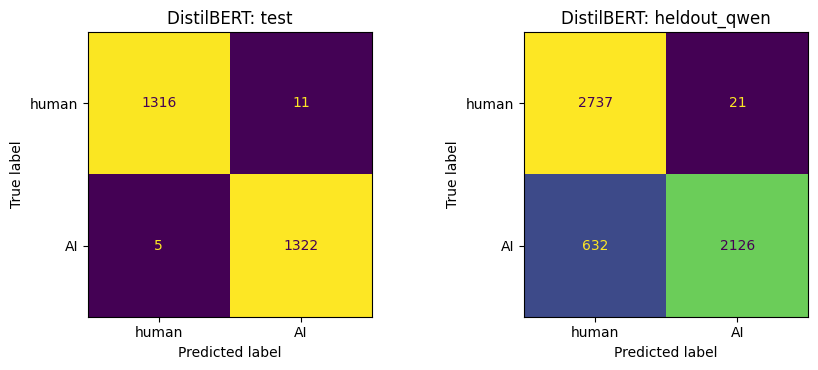

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, s in zip(axes, ["test", "heldout_qwen"]):
    ConfusionMatrixDisplay(confusion_matrix(splits[s].label, (probs[s] >= 0.5).astype(int)),
                           display_labels=["human", "AI"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"DistilBERT: {s}")
plt.tight_layout(); plt.savefig(RESULTS / "distilbert_confusion.png", dpi=120); plt.show()

## 5. All models

In [ ]:
m = pd.read_csv(RESULTS / "metrics.csv")
base = Path("/content/drive/MyDrive/TA2/results/03_baselines/metrics.csv")
if base.exists():
    m = pd.concat([pd.read_csv(base), m])
table = m.pivot_table(index="model", columns="split", values="accuracy", sort=False)[["val", "test", "heldout_qwen"]]
table["Qwen recall"] = m[m.split == "heldout_qwen"].set_index("model").recall_ai
table["FPR reserve"] = m[m.split == "reserve_human"].set_index("model").false_positive_rate
table.round(3).to_csv(RESULTS / "all_models.csv")
table.round(3)

split,val,test,heldout_qwen,Qwen recall,FPR reserve
model,,,,,
dummy,0.500,0.500,0.500,0.000,0.000
length only,0.528,0.530,0.478,0.405,0.446
simple features,0.905,0.916,0.813,0.713,0.119
TF-IDF + logistic regression,0.990,0.990,0.828,0.671,0.011
MLP tfidf (default),0.987,0.986,0.869,0.754,0.017
MLP tfidf (keep_case_punct),0.993,0.993,0.849,0.706,0.007
MLP tfidf (default_no_stopwords),0.983,0.981,0.811,0.632,0.010
CNN,0.986,0.988,0.819,0.650,0.010
BiLSTM,0.989,0.987,0.784,0.579,0.011
